# Choose the crop: does a 224 x 224 crop around the nucleus hold the whole cell?

MorphEm takes 224 x 224 pixel images.
Our previous crop was a square around each nucleus (the nucleus bounding box plus 25 pixels on each side) that MorphEm resized to 224 x 224, so every cell was zoomed by a different amount and large cells could be cut off.

Instead, we crop 224 x 224 pixels centered on each nucleus, so there is no resizing and every cell has the same scale.
The crop can include parts of neighboring cells, which is fine.
When the nucleus is near the edge of the image, we do not move the crop back inside the image (which would put the nucleus off center), so every crop is centered on its nucleus and the part of the crop outside the image is padded.

We run this notebook before the extraction (`2.extract_morphem_features.ipynb`), and it is the reason we use the 224 x 224 crop.
In this notebook, we check whether a 224 x 224 crop is big enough to hold the whole cell, how many crops are at the edge of the image (and how much of them is padding), and how many other single cells each crop includes.
For every single cell that CellProfiler segmented (before QC, since we extract the MorphEm features of every single cell and remove the ones that failed QC later), we find the **smallest square centered on the nucleus that holds the whole cell** (from the nucleus and cell bounding boxes from CellProfiler).
If that square is 224 pixels or smaller, the whole cell fits in a 224 x 224 crop.

## Import libraries

In [1]:
import pathlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from path_utils import get_root_dir

# root of the repository (found from the .git folder), so every path is built from the root
# and the notebook gives the same paths whether we run it from this folder or from the root
root_dir = get_root_dir()
module_dir = root_dir / "5.morphem_featurization"

## Define functions

In [2]:
def get_crop_boxes(
    center_x: np.ndarray, center_y: np.ndarray, side: np.ndarray, image_size: int, move_inside: bool
) -> tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray]:
    # square crops centered on the nucleus (the same as get_nucleocentric_crop_box in utils/morphem_utils.py)
    # move_inside=True moves crops at the edge back inside the image, as the previous crop did
    side = np.minimum(side, image_size)
    x_min = np.round(np.asarray(center_x) - side / 2)
    y_min = np.round(np.asarray(center_y) - side / 2)
    if move_inside:
        x_min = np.clip(x_min, 0, image_size - side)
        y_min = np.clip(y_min, 0, image_size - side)
    return x_min, x_min + side, y_min, y_min + side

## Set paths and variables

In [3]:
# Directory with the converted CellProfiler profiles (one folder per cell line, one parquet file per plate)
converted_dir = (root_dir / "4.preprocess_features/data/converted_profiles").resolve(strict=True)

# output paths for the figure and the summary per cell line
figure_path = module_dir / "figures/crop_size_224_fit_per_cell_line.png"
slide_figure_path = module_dir / "figures/crop_size_224_fit_per_cell_line_slide.png"
neighbor_figure_path = module_dir / "figures/crop_neighbors_per_cell_line_slide.png"
figure_path.parent.mkdir(parents=True, exist_ok=True)
summary_path = module_dir / "crop_evaluation/crop_size_summary.csv"
summary_path.parent.mkdir(parents=True, exist_ok=True)
neighbor_summary_path = module_dir / "crop_evaluation/crop_neighbor_summary.csv"
# per single cell counts, used to pick example crops in 1.view_224_crops.ipynb
single_cell_counts_path = module_dir / "crop_evaluation/crop_neighbor_counts_per_single_cell.parquet"

# size of the crop to test (MORPHEM_INPUT_SIZE in utils/morphem_utils.py)
crop_size = 224

# number of pixels added on each side of the nucleus bounding box in the previous crop (2.extract_morphem_features.ipynb)
expand_pixels = 25

# size of each FOV (height and width in pixels)
image_size = 1080

# center of the nucleus and bounding boxes of the nucleus and the cell from CellProfiler
bbox_columns = [
    f"{compartment}_AreaShape_BoundingBox{bound}_{axis}"
    for compartment in ("Nuclei", "Cells")
    for bound in ("Minimum", "Maximum")
    for axis in ("X", "Y")
]
# columns that identify each FOV (to find the other single cells in the same image)
fov_columns = ["Image_Metadata_Plate", "Image_Metadata_Well", "Image_Metadata_Site"]

size_columns = fov_columns + [
    "Metadata_Cells_Number_Object_Number",
    "Metadata_Nuclei_Location_Center_X",
    "Metadata_Nuclei_Location_Center_Y",
] + bbox_columns

## Load every single cell

We load the center of each nucleus and the bounding boxes of every single cell, before QC.

In [4]:
cell_line_dfs = []
for converted_path in sorted(converted_dir.glob("*/*_converted.parquet")):
    profile_df = pd.read_parquet(converted_path, columns=size_columns)
    profile_df["Metadata_cell_line"] = converted_path.parent.name
    cell_line_dfs.append(profile_df)
single_cell_df = pd.concat(cell_line_dfs, ignore_index=True)
print(f"{len(single_cell_df)} single cells from {single_cell_df['Metadata_cell_line'].nunique()} cell lines")

1420883 single cells from 54 cell lines


## Find the smallest square centered on the nucleus that holds the whole cell

The side of the square is two times the longest distance from the center of the nucleus to any edge of the cell, so the nucleus stays in the center.
We use the union of the nucleus and cell bounding boxes, since a few cell segmentations do not cover the whole nucleus.

For comparison, we also check whether the previous crop holds the whole cell.

We also count the 224 x 224 crops that go past the edge of the FOV.
We keep these crops centered on the nucleus and pad the part outside the image (the same as the extraction), so we also measure the fraction of each crop that is padding.

In [5]:
center_x = single_cell_df["Metadata_Nuclei_Location_Center_X"]
center_y = single_cell_df["Metadata_Nuclei_Location_Center_Y"]

# union of the nucleus and cell bounding boxes
min_x = np.minimum(single_cell_df["Nuclei_AreaShape_BoundingBoxMinimum_X"], single_cell_df["Cells_AreaShape_BoundingBoxMinimum_X"])
max_x = np.maximum(single_cell_df["Nuclei_AreaShape_BoundingBoxMaximum_X"], single_cell_df["Cells_AreaShape_BoundingBoxMaximum_X"])
min_y = np.minimum(single_cell_df["Nuclei_AreaShape_BoundingBoxMinimum_Y"], single_cell_df["Cells_AreaShape_BoundingBoxMinimum_Y"])
max_y = np.maximum(single_cell_df["Nuclei_AreaShape_BoundingBoxMaximum_Y"], single_cell_df["Cells_AreaShape_BoundingBoxMaximum_Y"])

# side of the smallest square centered on the nucleus that holds the whole cell
single_cell_df["whole_cell_square"] = 2 * np.maximum.reduce(
    [center_x - min_x, max_x - center_x, center_y - min_y, max_y - center_y]
)
single_cell_df["fits_in_224_crop"] = single_cell_df["whole_cell_square"] <= crop_size

# side of the previous crop (longest side of the nucleus bounding box plus expand_pixels on each side)
nucleus_side = np.maximum(
    single_cell_df["Nuclei_AreaShape_BoundingBoxMaximum_X"] - single_cell_df["Nuclei_AreaShape_BoundingBoxMinimum_X"],
    single_cell_df["Nuclei_AreaShape_BoundingBoxMaximum_Y"] - single_cell_df["Nuclei_AreaShape_BoundingBoxMinimum_Y"],
)
single_cell_df["fits_in_previous_crop"] = (
    single_cell_df["whole_cell_square"] <= nucleus_side.astype(int) + 2 * expand_pixels
)

# crops of each single cell: the 224 x 224 crop (centered on the nucleus, padded at the edge, the same as the
# extraction) and the previous crop (nucleus bounding box plus expand_pixels, moved back inside the image at the edge)
crop_boxes = {
    "224_crop": get_crop_boxes(center_x, center_y, np.full(len(single_cell_df), crop_size), image_size, move_inside=False),
    "previous_crop": get_crop_boxes(center_x, center_y, (nucleus_side.astype(int) + 2 * expand_pixels).to_numpy(), image_size, move_inside=True),
}

# fraction of each 224 x 224 crop that is outside the FOV (padding), and whether the crop is at the edge
x_min, x_max, y_min, y_max = crop_boxes["224_crop"]
inside_width = np.minimum(x_max, image_size) - np.maximum(x_min, 0)
inside_height = np.minimum(y_max, image_size) - np.maximum(y_min, 0)
single_cell_df["224_crop_pad_fraction"] = 1 - inside_width * inside_height / crop_size**2
single_cell_df["224_crop_at_edge"] = single_cell_df["224_crop_pad_fraction"] > 0

at_edge = single_cell_df["224_crop_at_edge"]
edge_padding = single_cell_df.loc[at_edge, "224_crop_pad_fraction"]
print(
    f"A {crop_size} x {crop_size} crop holds the whole cell for {single_cell_df['fits_in_224_crop'].mean():.1%} of single cells "
    f"(previous crop: {single_cell_df['fits_in_previous_crop'].mean():.1%})"
)
print(
    f"{at_edge.sum():,} of {len(single_cell_df):,} {crop_size} x {crop_size} crops ({at_edge.mean():.1%}) are at the edge of the FOV and padded "
    f"(padding of those crops: median {edge_padding.median():.1%}, 95th percentile {edge_padding.quantile(0.95):.1%}, maximum {edge_padding.max():.1%})"
)

A 224 x 224 crop holds the whole cell for 99.2% of single cells (previous crop: 68.2%)
424,549 of 1,420,883 224 x 224 crops (29.9%) are at the edge of the FOV and padded (padding of those crops: median 20.1%, 95th percentile 41.5%, maximum 70.3%)


## Summarize per cell line

In [6]:
summary_df = (
    single_cell_df.groupby("Metadata_cell_line")
    .agg(
        n_single_cells=("whole_cell_square", "size"),
        whole_cell_square_median=("whole_cell_square", "median"),
        whole_cell_square_p99=("whole_cell_square", lambda side: side.quantile(0.99)),
        percent_fit_in_224_crop=("fits_in_224_crop", "mean"),
        percent_fit_in_previous_crop=("fits_in_previous_crop", "mean"),
        n_224_crop_at_edge=("224_crop_at_edge", "sum"),
        percent_224_crop_at_edge=("224_crop_at_edge", "mean"),
    )
    .sort_values("whole_cell_square_median")
)
percent_columns = [col for col in summary_df.columns if col.startswith("percent_")]
summary_df[percent_columns] = summary_df[percent_columns] * 100
summary_df = summary_df.round(1)

summary_df.to_csv(summary_path)
print(f"Saved {summary_path}")
summary_df

Saved /media/18tbdrive/1.Github_Repositories/pccma_atlas_image_profiling/5.morphem_featurization/crop_evaluation/crop_size_summary.csv


,n_single_cells,whole_cell_square_median,whole_cell_square_p99,percent_fit_in_224_crop,percent_fit_in_previous_crop,n_224_crop_at_edge,percent_224_crop_at_edge
Metadata_cell_line,,,,,,,
CHLA203,22707,35.5,82.3,100.0,98.6,7946,35.0
D425,18934,38.6,84.2,100.0,98.2,6231,32.9
CHLA194,5345,40.1,120.6,99.9,98.0,1724,32.3
SK-N-MC,43763,42.6,95.6,100.0,96.9,14316,32.7
KP-N-YN,73582,42.9,125.6,100.0,93.1,24134,32.8
TC71,91699,43.3,128.3,99.9,87.7,30205,32.9
PBT04_FHTC,3722,48.0,203.6,99.4,81.5,1190,32.0
D283,56767,49.7,207.6,99.3,91.7,17621,31.0
CHLA25,13169,50.7,139.4,99.9,90.4,4272,32.4


## Plot whether the whole cell fits in a 224 x 224 crop

Each box is the size of the smallest square centered on the nucleus that holds the whole cell, for one cell line.
Cells to the left of the dashed line fit in a 224 x 224 crop.
The boxes show the 25th to 75th percentiles and the median, and the whiskers show the 1st to 99th percentiles.
The numbers on the right are the percent of single cells in each cell line that fit.

/tmp/ipykernel_2878720/2316477728.py:10: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(


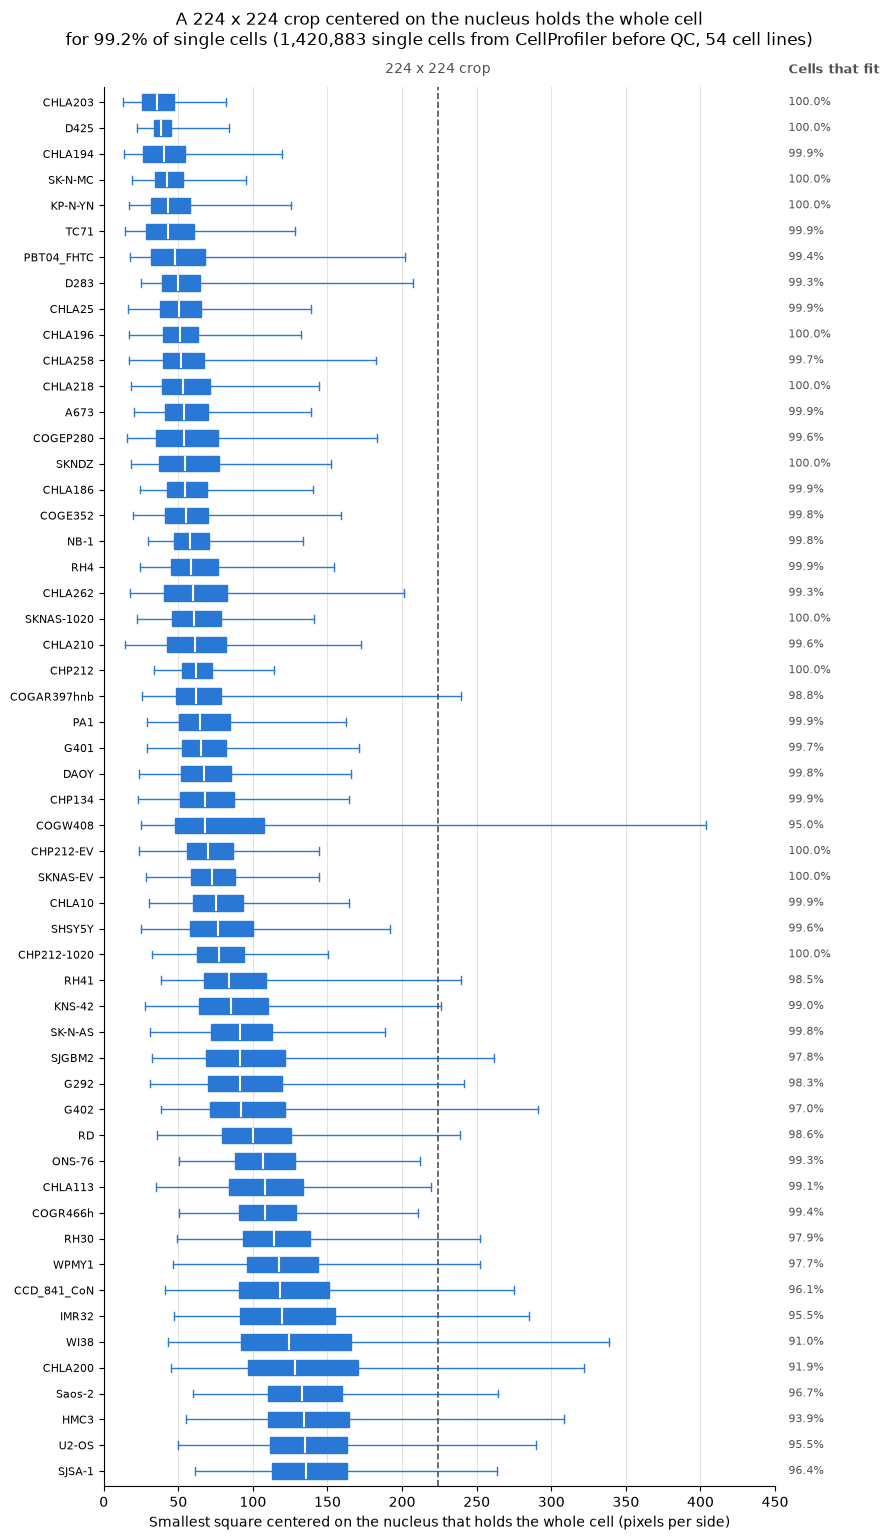

In [7]:
box_color = "#2a78d6"
ink_color = "#52514e"

cell_lines = summary_df.index.tolist()
positions = np.arange(len(cell_lines))

fig, ax = plt.subplots(figsize=(9, 0.25 * len(cell_lines) + 2))

# one horizontal box per cell line (whiskers at the 1st and 99th percentiles, no outliers)
ax.boxplot(
    [single_cell_df.loc[single_cell_df["Metadata_cell_line"] == cell_line, "whole_cell_square"].to_numpy() for cell_line in cell_lines],
    positions=positions,
    widths=0.6,
    vert=False,
    whis=(1, 99),
    showfliers=False,
    patch_artist=True,
    boxprops={"facecolor": box_color, "edgecolor": box_color, "linewidth": 1},
    medianprops={"color": "white", "linewidth": 1.5},
    whiskerprops={"color": box_color, "linewidth": 1},
    capprops={"color": box_color, "linewidth": 1},
)

# 224 x 224 crop
ax.axvline(crop_size, color=ink_color, linestyle="--", linewidth=1.2)
ax.text(crop_size, -1, f"{crop_size} x {crop_size} crop", color=ink_color, fontsize=10, ha="center", va="bottom")

# percent of single cells that fit, to the right of the plot (past the longest whisker, rounded up to 50 pixels)
x_max = np.ceil(summary_df["whole_cell_square_p99"].max() / 50) * 50
ax.text(x_max * 1.02, -1, "Cells that fit", color=ink_color, fontsize=9, fontweight="bold", ha="left", va="bottom")
for position, cell_line in zip(positions, cell_lines):
    ax.text(x_max * 1.02, position, f"{summary_df.loc[cell_line, 'percent_fit_in_224_crop']:.1f}%", color=ink_color, fontsize=8, ha="left", va="center")

ax.set_xlim(0, x_max)
ax.set_ylim(-0.6, len(cell_lines) - 0.4)
ax.invert_yaxis()
ax.set_yticks(positions)
ax.set_yticklabels(cell_lines, fontsize=8)
ax.set_xlabel("Smallest square centered on the nucleus that holds the whole cell (pixels per side)")
ax.grid(axis="x", color="#e4e3df", linewidth=0.8)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)

ax.set_title(
    f"A {crop_size} x {crop_size} crop centered on the nucleus holds the whole cell\n"
    f"for {single_cell_df['fits_in_224_crop'].mean():.1%} of single cells "
    f"({len(single_cell_df):,} single cells from CellProfiler before QC, {len(cell_lines)} cell lines)",
    pad=30,
)

fig.tight_layout()
fig.savefig(figure_path, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

## Plot a landscape version for slides

The same data as above with the cell lines along the x-axis and larger fonts, so it fits a 16:9 slide.
The top panel shows the size of the smallest square centered on the nucleus that holds the whole cell (whiskers at the 1st and 99th percentiles), and the bottom panel shows the percent of single cells in each cell line that fit in a 224 x 224 crop.

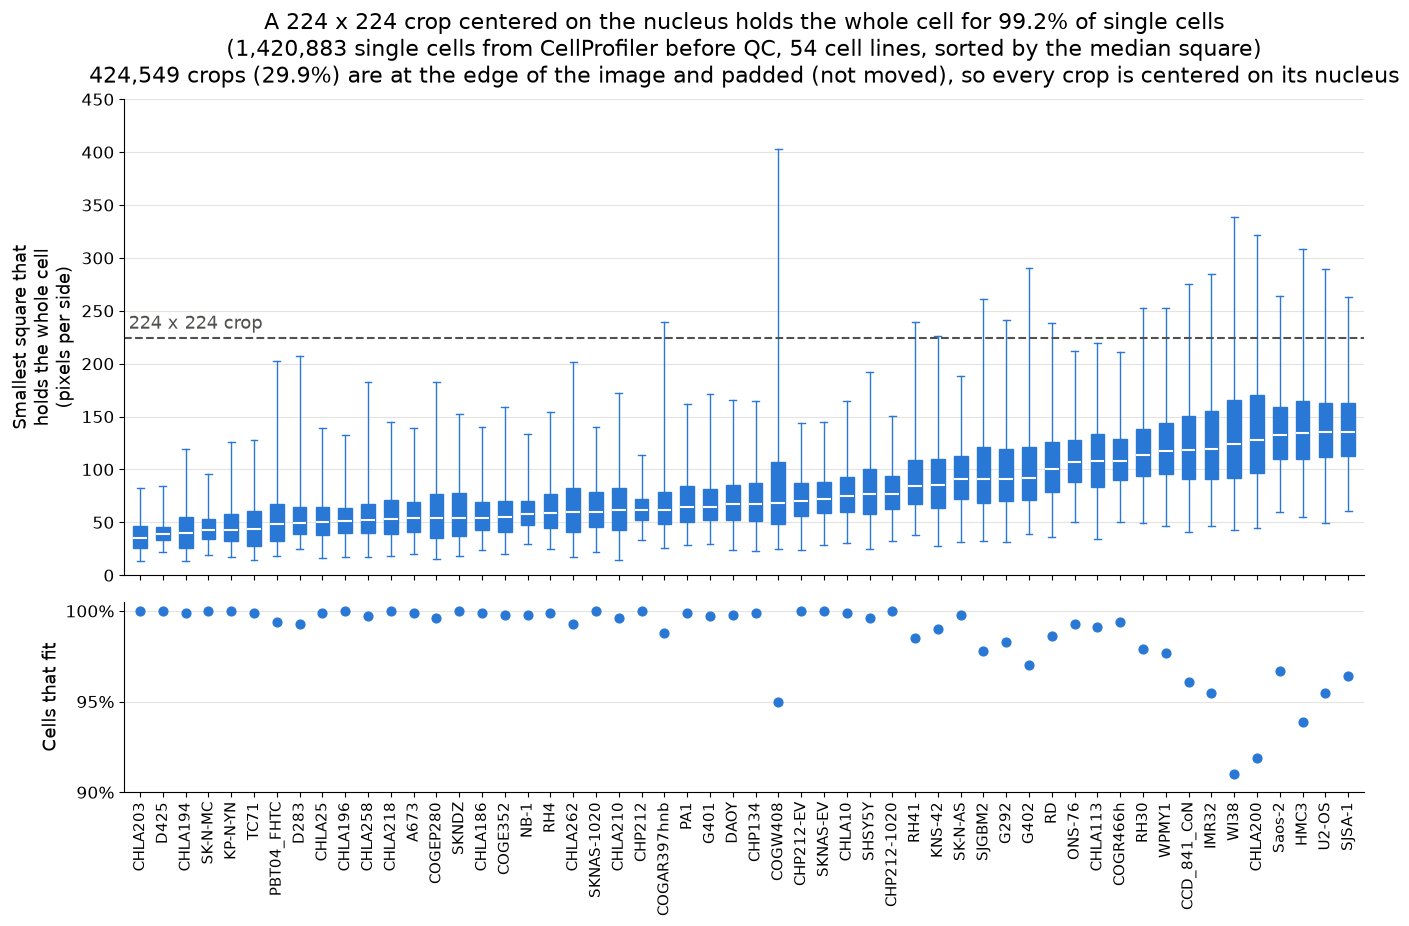

In [8]:
fig, (ax_size, ax_fit) = plt.subplots(
    2, 1, figsize=(16, 9), sharex=True, gridspec_kw={"height_ratios": [3, 1.2], "hspace": 0.08}
)

# one vertical box per cell line (whiskers at the 1st and 99th percentiles, no outliers)
ax_size.boxplot(
    [single_cell_df.loc[single_cell_df["Metadata_cell_line"] == cell_line, "whole_cell_square"].to_numpy() for cell_line in cell_lines],
    positions=positions,
    widths=0.6,
    whis=(1, 99),
    showfliers=False,
    patch_artist=True,
    boxprops={"facecolor": box_color, "edgecolor": box_color, "linewidth": 1},
    medianprops={"color": "white", "linewidth": 1.5},
    whiskerprops={"color": box_color, "linewidth": 1},
    capprops={"color": box_color, "linewidth": 1},
)
ax_size.axhline(crop_size, color=ink_color, linestyle="--", linewidth=1.5)
ax_size.text(-0.5, crop_size + 5, f"{crop_size} x {crop_size} crop", color=ink_color, fontsize=13, ha="left", va="bottom")
ax_size.set_ylim(0, x_max)
ax_size.set_ylabel("Smallest square that\nholds the whole cell\n(pixels per side)", fontsize=13)

# percent of single cells that fit in each cell line
ax_fit.scatter(positions, summary_df["percent_fit_in_224_crop"], color=box_color, s=40, zorder=3)
ax_fit.set_ylim(90, 100.5)
ax_fit.set_yticks([90, 95, 100])
ax_fit.set_yticklabels(["90%", "95%", "100%"])
ax_fit.set_ylabel("Cells that fit", fontsize=13)

for ax in (ax_size, ax_fit):
    ax.grid(axis="y", color="#e4e3df", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(axis="y", labelsize=12)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
ax_fit.set_xlim(-0.7, len(cell_lines) - 0.3)
ax_fit.set_xticks(positions)
ax_fit.set_xticklabels(cell_lines, rotation=90, fontsize=11)

ax_size.set_title(
    f"A {crop_size} x {crop_size} crop centered on the nucleus holds the whole cell for {single_cell_df['fits_in_224_crop'].mean():.1%} of single cells\n"
    f"({len(single_cell_df):,} single cells from CellProfiler before QC, {len(cell_lines)} cell lines, sorted by the median square)\n"
    f"{single_cell_df['224_crop_at_edge'].sum():,} crops ({single_cell_df['224_crop_at_edge'].mean():.1%}) are at the edge of the image and padded (not moved), so every crop is centered on its nucleus",
    fontsize=16,
    pad=12,
)

fig.savefig(slide_figure_path, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

## Count the other single cells in each crop

A crop centered on one nucleus can also include other single cells.
For each single cell, we place its crop the same way as the extraction (centered on the nucleus, and not moved at the edge of the image) and count the other single cells from the same FOV whose **nucleus center** is inside the crop.
We count nucleus centers, so a neighbor only counts when a large part of it is in the crop (not just the tip of a protrusion).

We count the other single cells for both a 224 x 224 crop and the previous crop (the nucleus bounding box plus 25 pixels on each side), since the previous crop can also include neighbors.
These counts are before QC, so they also include segmentation errors (e.g., a nucleus split in two).

In [9]:
nucleus_x = center_x.to_numpy()
nucleus_y = center_y.to_numpy()

# number of other nucleus centers inside the crop of each single cell (compared within each FOV)
for crop_name, (x_min, x_max, y_min, y_max) in crop_boxes.items():
    other_cells = np.zeros(len(single_cell_df), dtype=int)
    for fov_index in single_cell_df.groupby(["Metadata_cell_line"] + fov_columns, sort=False).indices.values():
        inside = (
            (nucleus_x[fov_index][None, :] >= x_min[fov_index][:, None])
            & (nucleus_x[fov_index][None, :] < x_max[fov_index][:, None])
            & (nucleus_y[fov_index][None, :] >= y_min[fov_index][:, None])
            & (nucleus_y[fov_index][None, :] < y_max[fov_index][:, None])
        )
        # do not count the single cell of the crop
        np.fill_diagonal(inside, False)
        other_cells[fov_index] = inside.sum(axis=1)
    single_cell_df[f"other_cells_in_{crop_name}"] = other_cells

for crop_name in crop_boxes:
    other_cells = single_cell_df[f"other_cells_in_{crop_name}"]
    print(
        f"{crop_name}: {(other_cells > 0).mean():.1%} of crops include at least one other single cell "
        f"(median {other_cells.median():.0f} other single cells, 95th percentile {other_cells.quantile(0.95):.0f})"
    )

# save the counts of each single cell to pick example crops later
single_cell_df[
    ["Metadata_cell_line"] + fov_columns + ["Metadata_Cells_Number_Object_Number", "whole_cell_square", "fits_in_224_crop", "224_crop_at_edge", "224_crop_pad_fraction"]
    + [f"other_cells_in_{crop_name}" for crop_name in crop_boxes]
].to_parquet(single_cell_counts_path, index=False)
print(f"Saved {single_cell_counts_path}")

224_crop: 99.3% of crops include at least one other single cell (median 21 other single cells, 95th percentile 65)
previous_crop: 87.8% of crops include at least one other single cell (median 3 other single cells, 95th percentile 10)


Saved /media/18tbdrive/1.Github_Repositories/pccma_atlas_image_profiling/5.morphem_featurization/crop_evaluation/crop_neighbor_counts_per_single_cell.parquet


In [10]:
neighbor_summary_df = (
    single_cell_df.groupby("Metadata_cell_line")
    .agg(
        n_single_cells=("other_cells_in_224_crop", "size"),
        other_cells_in_224_crop_median=("other_cells_in_224_crop", "median"),
        other_cells_in_224_crop_p95=("other_cells_in_224_crop", lambda count: count.quantile(0.95)),
        other_cells_in_previous_crop_median=("other_cells_in_previous_crop", "median"),
        percent_224_crop_with_other_cells=("other_cells_in_224_crop", lambda count: (count > 0).mean() * 100),
        percent_previous_crop_with_other_cells=("other_cells_in_previous_crop", lambda count: (count > 0).mean() * 100),
    )
    .sort_values("other_cells_in_224_crop_median")
    .round(1)
)
neighbor_summary_df.to_csv(neighbor_summary_path)
print(f"Saved {neighbor_summary_path}")
neighbor_summary_df

Saved /media/18tbdrive/1.Github_Repositories/pccma_atlas_image_profiling/5.morphem_featurization/crop_evaluation/crop_neighbor_summary.csv


,n_single_cells,other_cells_in_224_crop_median,other_cells_in_224_crop_p95,other_cells_in_previous_crop_median,percent_224_crop_with_other_cells,percent_previous_crop_with_other_cells
Metadata_cell_line,,,,,,
PBT04_FHTC,3722,2.0,9.0,0.0,83.3,48.4
HMC3,6167,3.0,8.0,0.0,91.6,29.2
RH41,7658,3.0,8.0,0.0,93.8,29.4
U2-OS,27032,3.0,9.0,0.0,92.5,38.6
CHP134,11367,5.0,23.0,1.0,96.5,55.1
CHLA113,5949,5.0,13.0,1.0,94.5,68.1
CHLA196,1013,5.0,17.0,4.0,91.9,91.0
CHLA200,12378,5.0,11.0,0.0,98.5,48.3
SJSA-1,10729,5.0,10.0,0.0,98.2,32.3


## Plot the other single cells in each crop

The top panel shows the number of other nuclei centers in each crop (not counting the nucleus the crop is centered on) per cell line (boxes at the 25th to 75th percentiles and the median, whiskers at the 5th and 95th percentiles), for the 224 x 224 crop and the previous crop.
The bottom panel shows the percent of crops in each cell line that include at least one other nucleus.
The cell lines are sorted by the median number of other single cells in the 224 x 224 crop.

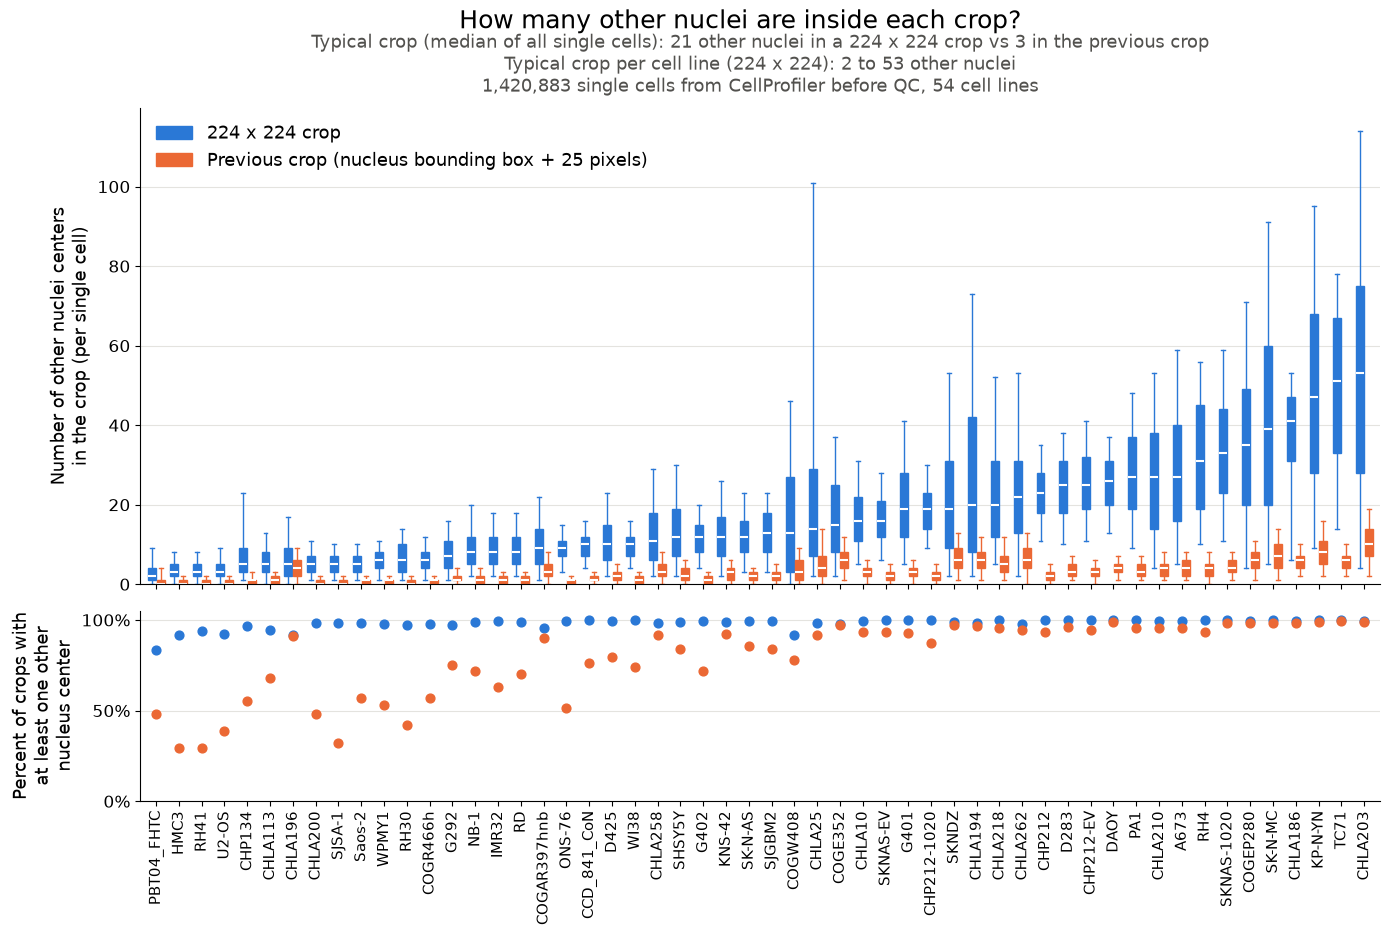

In [11]:
previous_color = "#eb6834"
neighbor_cell_lines = neighbor_summary_df.index.tolist()
neighbor_positions = np.arange(len(neighbor_cell_lines))
box_offset = 0.2

fig, (ax_count, ax_percent) = plt.subplots(
    2, 1, figsize=(16, 9), sharex=True, gridspec_kw={"height_ratios": [3, 1.2], "hspace": 0.08}
)

# one vertical box per cell line and crop (whiskers at the 5th and 95th percentiles, no outliers)
for crop_name, offset, color in (("224_crop", -box_offset, box_color), ("previous_crop", box_offset, previous_color)):
    ax_count.boxplot(
        [single_cell_df.loc[single_cell_df["Metadata_cell_line"] == cell_line, f"other_cells_in_{crop_name}"].to_numpy() for cell_line in neighbor_cell_lines],
        positions=neighbor_positions + offset,
        widths=0.35,
        whis=(5, 95),
        showfliers=False,
        patch_artist=True,
        boxprops={"facecolor": color, "edgecolor": color, "linewidth": 1},
        medianprops={"color": "white", "linewidth": 1.5},
        whiskerprops={"color": color, "linewidth": 1},
        capprops={"color": color, "linewidth": 1},
    )
    ax_percent.scatter(
        neighbor_positions,
        neighbor_summary_df[f"percent_{crop_name}_with_other_cells"],
        color=color,
        s=40,
        zorder=3,
    )
ax_count.set_ylim(bottom=0)
ax_count.set_ylabel("Number of other nuclei centers\nin the crop (per single cell)", fontsize=13)
ax_percent.set_ylim(0, 105)
ax_percent.set_yticks([0, 50, 100])
ax_percent.set_yticklabels(["0%", "50%", "100%"])
ax_percent.set_ylabel("Percent of crops with\nat least one other\nnucleus center", fontsize=13)

for ax in (ax_count, ax_percent):
    ax.grid(axis="y", color="#e4e3df", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(axis="y", labelsize=12)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
ax_percent.set_xlim(-0.7, len(neighbor_cell_lines) - 0.3)
ax_percent.set_xticks(neighbor_positions)
ax_percent.set_xticklabels(neighbor_cell_lines, rotation=90, fontsize=11)

handles = [
    plt.Rectangle((0, 0), 1, 1, color=box_color, label=f"{crop_size} x {crop_size} crop"),
    plt.Rectangle((0, 0), 1, 1, color=previous_color, label=f"Previous crop (nucleus bounding box + {expand_pixels} pixels)"),
]
ax_count.legend(handles=handles, loc="upper left", frameon=False, fontsize=13)

# headline, then the numbers on their own lines
fig.suptitle("How many other nuclei are inside each crop?", fontsize=18, y=0.99)
ax_count.set_title(
    f"Typical crop (median of all single cells): {single_cell_df['other_cells_in_224_crop'].median():.0f} other nuclei in a {crop_size} x {crop_size} crop "
    f"vs {single_cell_df['other_cells_in_previous_crop'].median():.0f} in the previous crop\n"
    f"Typical crop per cell line ({crop_size} x {crop_size}): {neighbor_summary_df['other_cells_in_224_crop_median'].min():.0f} to "
    f"{neighbor_summary_df['other_cells_in_224_crop_median'].max():.0f} other nuclei\n"
    f"{len(single_cell_df):,} single cells from CellProfiler before QC, {len(neighbor_cell_lines)} cell lines",
    fontsize=13,
    color=ink_color,
    pad=12,
)

fig.savefig(neighbor_figure_path, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()